# Drawing QASP quantum circuits

This notebook contains drawing-only examples for QASP policies, quantum kernels, and directly constructed circuits. Each example exports publication-ready Quantikz/TikZ and renders it inside Jupyter when a LaTeX installation is available.


## Requirements

The Python environment needs QASP, PennyLane, Torch, and IPython. Rendering additionally needs `pdflatex` with the `quantikz` package. PDF-to-PNG conversion uses `pdftoppm` when available and falls back to the macOS `sips` command.

If QASP was edited while this notebook was open, restart the Jupyter kernel before running the cells.


In [1]:
from pathlib import Path
import copy
import os
import shutil
import subprocess

import numpy as np
import torch
from IPython.display import Code, Image, IFrame, display

from qasp import (
    AngleAnsatz,
    AngleEmbedding,
    CircuitBuilder,
    create_kernel,
    create_model,
    draw_kernel,
    draw_model,
)

print("Torch:", torch.__version__)
print("pdflatex:", shutil.which("pdflatex") or "not found")
print("PDF converter:", shutil.which("pdftoppm") or shutil.which("sips") or "not found")


Torch: 2.14.1
pdflatex: /opt/homebrew/bin/pdflatex
PDF converter: /usr/bin/sips


In [2]:
def display_tikz(tikz, name, width=1600, show_source=False):
    """Save standalone TikZ, compile it, and display the result in Jupyter."""
    output_dir = Path("tikz_output")
    output_dir.mkdir(exist_ok=True)

    tex_path = output_dir / f"{name}.tex"
    pdf_path = output_dir / f"{name}.pdf"
    png_path = output_dir / f"{name}.png"
    tex_path.write_text(tikz, encoding="utf-8")

    if show_source:
        display(Code(tikz, language="latex"))

    pdflatex = shutil.which("pdflatex")
    if pdflatex is None:
        print(f"Saved {tex_path}. Install a TeX distribution to render it.")
        return {"tex": tex_path}

    completed = subprocess.run(
        [pdflatex, "-interaction=nonstopmode", "-halt-on-error", tex_path.name],
        cwd=output_dir,
        capture_output=True,
        text=True,
    )
    if completed.returncode != 0:
        print(completed.stdout[-4000:])
        raise RuntimeError(f"LaTeX compilation failed for {tex_path}")

    pdftoppm = os.environ.get("QASP_PDFTOPPM") or shutil.which("pdftoppm")
    sips = shutil.which("sips")
    if pdftoppm is not None:
        subprocess.run(
            [pdftoppm, "-png", "-singlefile", "-r", "200", pdf_path.name, name],
            cwd=output_dir,
            check=True,
            capture_output=True,
            text=True,
        )
    elif sips is not None:
        subprocess.run(
            [sips, "-s", "format", "png", "-Z", str(width), pdf_path.name,
             "--out", png_path.name],
            cwd=output_dir,
            check=True,
            capture_output=True,
            text=True,
        )
    else:
        print(f"Saved {pdf_path}; no PDF-to-PNG converter was found.")
        display(IFrame(str(pdf_path), width="100%", height=450))
        return {"tex": tex_path, "pdf": pdf_path}

    display(Image(filename=str(png_path)))
    return {"tex": tex_path, "pdf": pdf_path, "png": png_path}


In [3]:
PASTEL_COLORS = {
    "single": "DCECF8",       # light blue
    "two": "E4D8F2",          # soft purple
    "multi": "EEE2F7",        # pale violet
    "measurement": "E8E5F5", # light lavender
}

FULL_TIKZ = {
    "standalone": True,
    "symbolic_parameters": True,
    "gate_colors": PASTEL_COLORS,
}

COMPRESSED_TIKZ = {
    **FULL_TIKZ,
    "compress": True,
    "max_explicit_layers": 4,
}


## 1. IQP policy

The first drawing shows every gate. The second keeps the complete first variational layer inside a dashed region and replaces the later layers with full-register unitary boxes.


In [4]:
N_QUBITS = 4
N_FEATURES = 4
zero_input = torch.zeros(N_FEATURES)

policy_common = {
    "feature_map": "AngleEmbedding",
    "feature_map_config": {
        "features": N_FEATURES,
        "rotations": "Y",
        "imprimitive_pattern": "chain",
    },
    "n_actions": 2,
    "init": "zeros",
    "policy": "parity-like",
    "device": "default.qubit",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    "parity_cnot_decomposition": False,
}

iqp_policy_config = {
    **copy.deepcopy(policy_common),
    "ansatz": "IQPAnsatz",
    "ansatz_config": {
        "n_layers": 3,
        "imprimitive_pattern": "ring",
        "reuploading": False,
    },
}

iqp_policy = create_model("PQCBorn", iqp_policy_config, n_qubits=N_QUBITS)


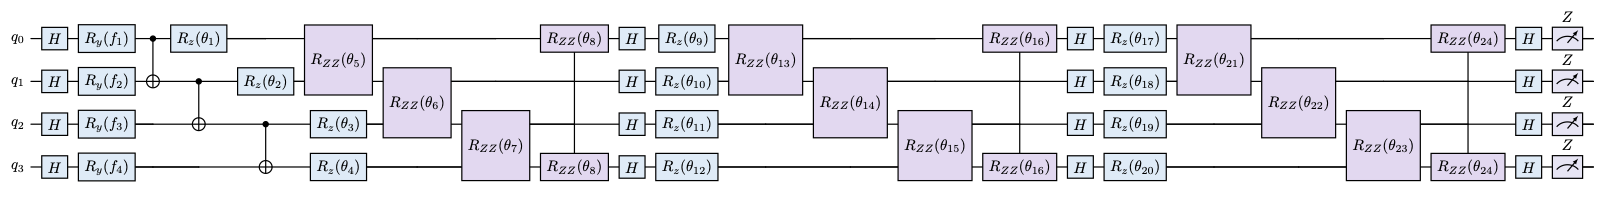

{'tex': PosixPath('tikz_output/iqp_policy_full.tex'),
 'pdf': PosixPath('tikz_output/iqp_policy_full.pdf'),
 'png': PosixPath('tikz_output/iqp_policy_full.png')}

In [5]:
iqp_policy_full = draw_model(
    model=iqp_policy,
    inputs=zero_input,
    output="tikz",
    tikz_options=FULL_TIKZ,
)
display_tikz(iqp_policy_full, "iqp_policy_full")


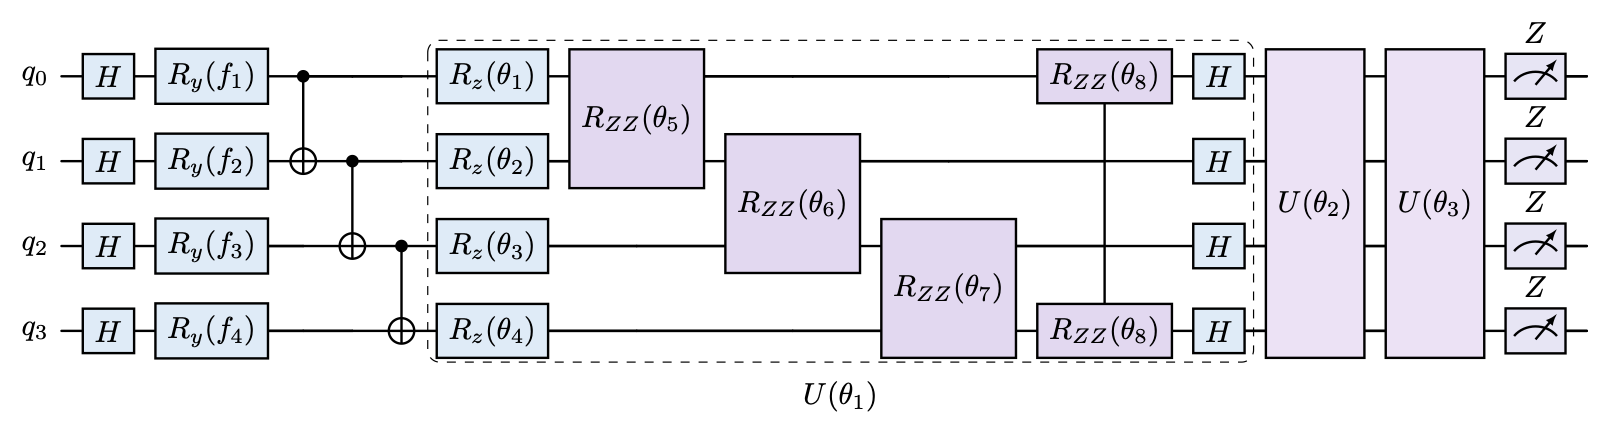

{'tex': PosixPath('tikz_output/iqp_policy_compressed.tex'),
 'pdf': PosixPath('tikz_output/iqp_policy_compressed.pdf'),
 'png': PosixPath('tikz_output/iqp_policy_compressed.png')}

In [6]:
iqp_policy_compressed = draw_model(
    model=iqp_policy,
    inputs=zero_input,
    output="tikz",
    tikz_options=COMPRESSED_TIKZ,
)
display_tikz(iqp_policy_compressed, "iqp_policy_compressed")


## 2. Policy with an arbitrary AngleAnsatz

Here the variational layer mixes one- and two-qubit Pauli rotations. In particular, the `ZZ` rotations are rendered as symmetric two-qubit gates rather than controlled rotations.


In [7]:
angle_policy_config = {
    **copy.deepcopy(policy_common),
    "ansatz": "AngleAnsatz",
    "ansatz_config": {
        "n_layers": 3,
        "rotations": [
            "ZZ 0 1",
            "ZZ 1 2",
            "ZZ 2 3",
            "Z 0",
            "Y 1",
            "X 2",
        ],
        "reuploading": False,
        "include_imprimitive": False,
        "imprimitive": "CZ",
        "imprimitive_pattern": "chain",
        "include_final_imprimitive": False,
    },
}

angle_policy = create_model(
    "PQCBorn", angle_policy_config, n_qubits=N_QUBITS
)


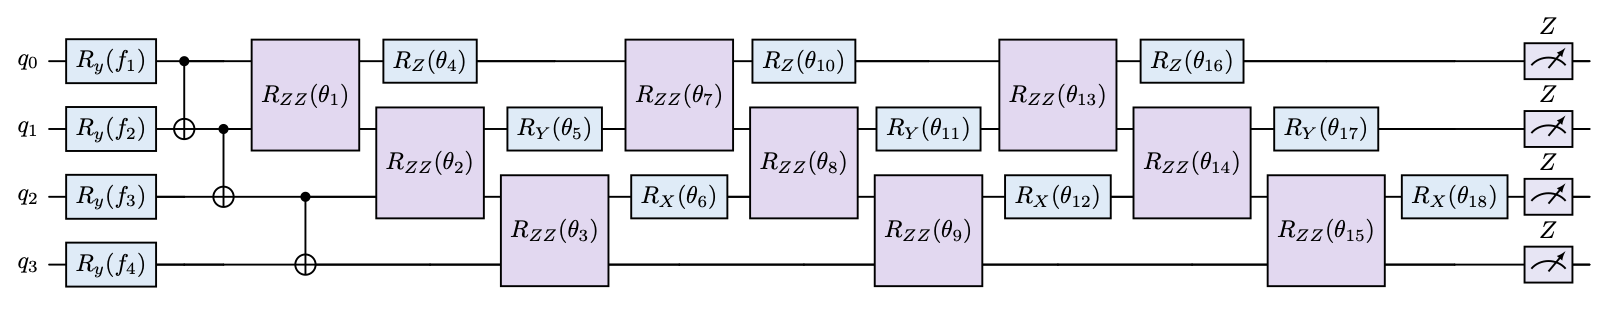

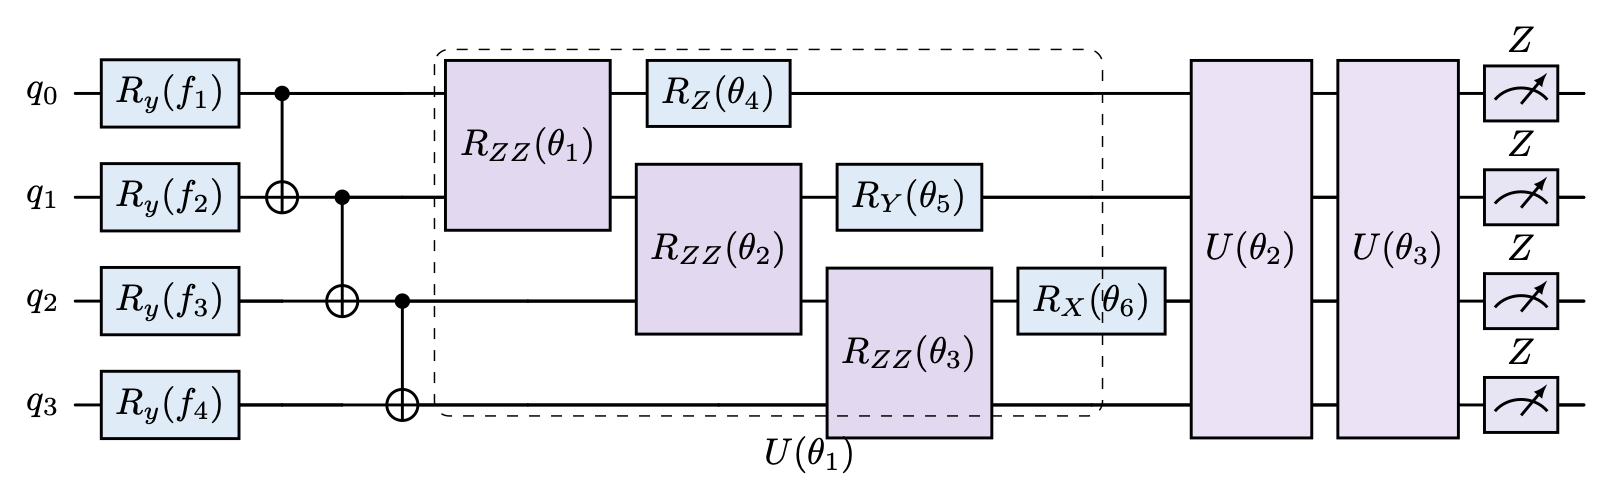

{'tex': PosixPath('tikz_output/angle_policy_compressed.tex'),
 'pdf': PosixPath('tikz_output/angle_policy_compressed.pdf'),
 'png': PosixPath('tikz_output/angle_policy_compressed.png')}

In [8]:
angle_policy_full = draw_model(
    model=angle_policy,
    inputs=zero_input,
    output="tikz",
    tikz_options=FULL_TIKZ,
)
display_tikz(angle_policy_full, "angle_policy_full")

angle_policy_compressed = draw_model(
    model=angle_policy,
    inputs=zero_input,
    output="tikz",
    tikz_options=COMPRESSED_TIKZ,
)
display_tikz(angle_policy_compressed, "angle_policy_compressed")


## 3. IQP quantum kernels

Fidelity and local-fidelity drawings take two samples, `x` and `y`. Their compressed diagrams include the forward unitary blocks and the matching adjoint blocks in reverse order. A projected kernel only takes `x`.


In [9]:
x = np.array([0.10, 0.20, 0.30, 0.40])
y = np.array([0.40, 0.30, 0.20, 0.10])

kernel_common = {
    "feature_map": "AngleEmbedding",
    "feature_map_config": {
        "features": N_FEATURES,
        "rotations": "Y",
        "imprimitive_pattern": "chain",
    },
    "ansatz": "IQPAnsatz",
    "ansatz_config": {
        "n_layers": 3,
        "imprimitive_pattern": "ring",
        "reuploading": False,
    },
    "init": "zeros",
    "device": "default.qubit",
}


### 3.1 Global fidelity kernel


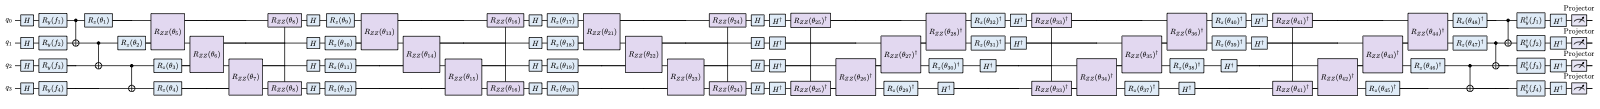

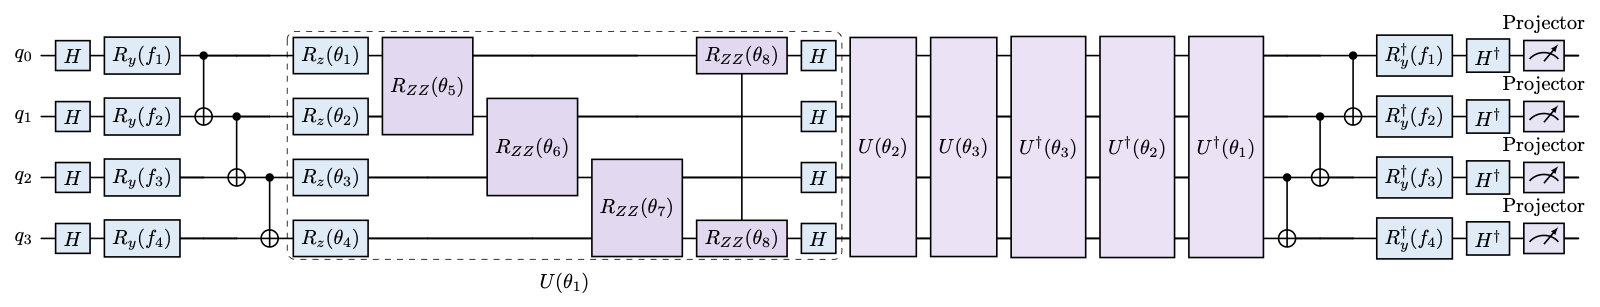

{'tex': PosixPath('tikz_output/fidelity_kernel_compressed.tex'),
 'pdf': PosixPath('tikz_output/fidelity_kernel_compressed.pdf'),
 'png': PosixPath('tikz_output/fidelity_kernel_compressed.png')}

In [10]:
fidelity_kernel = create_kernel(
    {**copy.deepcopy(kernel_common), "kernel_type": "fidelity"},
    n_qubits=N_QUBITS,
)

fidelity_full = draw_kernel(
    kernel=fidelity_kernel,
    x=x,
    y=y,
    output="tikz",
    tikz_options=FULL_TIKZ,
)
display_tikz(fidelity_full, "fidelity_kernel_full")

fidelity_compressed = draw_kernel(
    kernel=fidelity_kernel,
    x=x,
    y=y,
    output="tikz",
    tikz_options=COMPRESSED_TIKZ,
)
display_tikz(fidelity_compressed, "fidelity_kernel_compressed")


### 3.2 Local-fidelity kernel with a full Pauli-Z string

The observable `ZZZZ 0 1 2 3` produces a measurement box on every qubit.


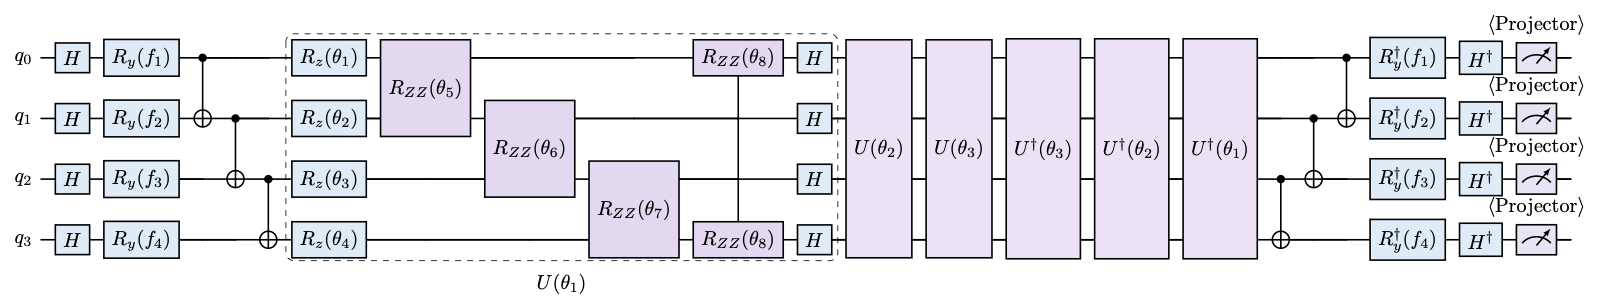

{'tex': PosixPath('tikz_output/local_fidelity_kernel.tex'),
 'pdf': PosixPath('tikz_output/local_fidelity_kernel.pdf'),
 'png': PosixPath('tikz_output/local_fidelity_kernel.png')}

In [11]:
local_config = {
    **copy.deepcopy(kernel_common),
    "kernel_type": "fidelity",
    "projectors": ["P 0", "P 1", "P 2", "P 3"],
}
local_kernel = create_kernel(local_config, n_qubits=N_QUBITS)

local_tikz = draw_kernel(
    kernel=local_kernel,
    x=x,
    y=y,
    output="tikz",
    tikz_options=COMPRESSED_TIKZ,
)
display_tikz(local_tikz, "local_fidelity_kernel")


### 3.3 Projected quantum kernel


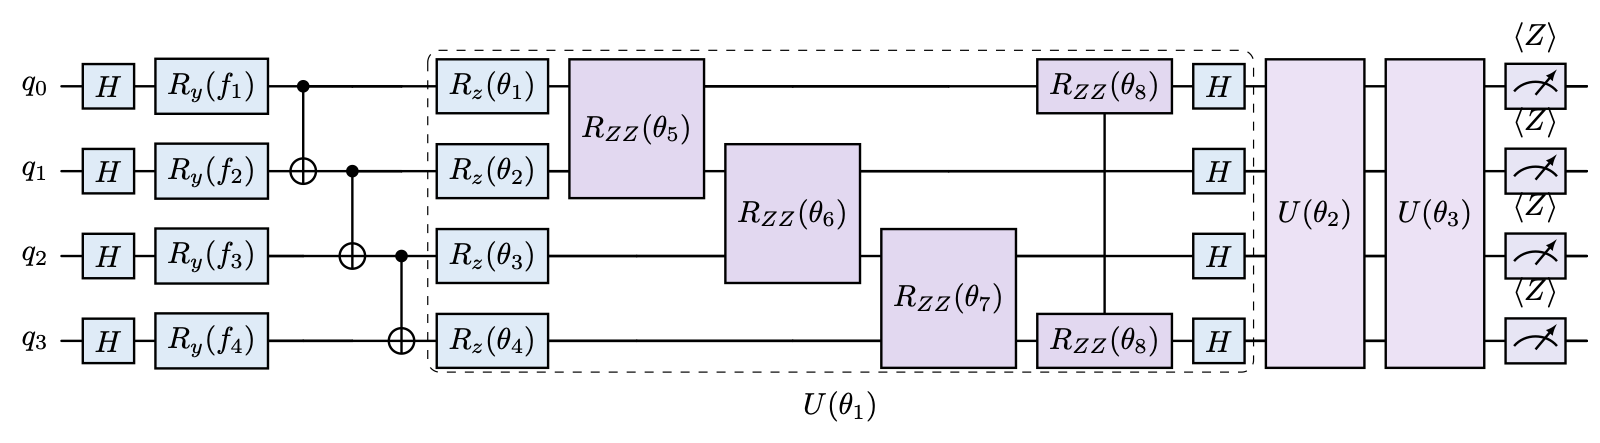

{'tex': PosixPath('tikz_output/projected_kernel.tex'),
 'pdf': PosixPath('tikz_output/projected_kernel.pdf'),
 'png': PosixPath('tikz_output/projected_kernel.png')}

In [12]:
projected_config = {
    **copy.deepcopy(kernel_common),
    "kernel_type": "projected",
    "observables": ["Z 0", "Z 1", "Z 2", "Z 3"],
    "gamma": 0.5,
}
projected_kernel = create_kernel(projected_config, n_qubits=N_QUBITS)

projected_tikz = draw_kernel(
    kernel=projected_kernel,
    x=x,
    output="tikz",
    tikz_options=COMPRESSED_TIKZ,
)
display_tikz(projected_tikz, "projected_kernel")


## 4. Circuit assembled directly with QASP

This example bypasses the policy and kernel factories. It combines a custom multi-Pauli feature map, a repeated AngleAnsatz, and a tensor-product Pauli-Z measurement.


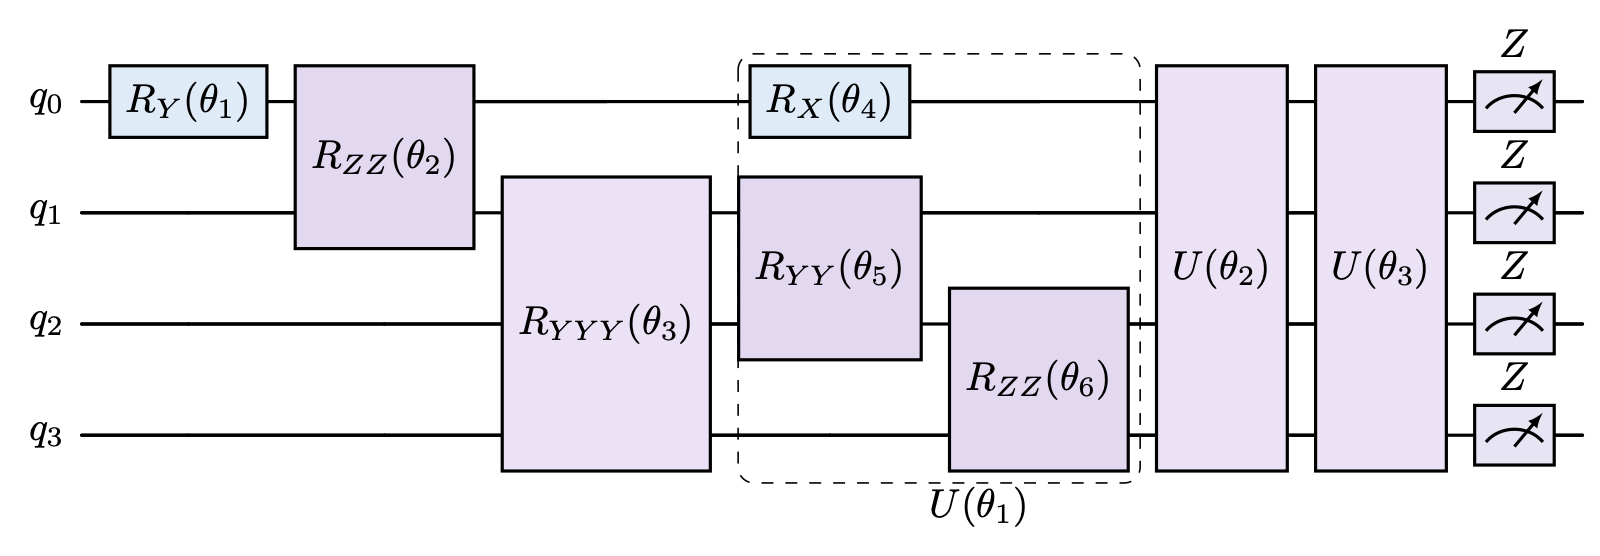

{'tex': PosixPath('tikz_output/custom_qasp_circuit.tex'),
 'pdf': PosixPath('tikz_output/custom_qasp_circuit.pdf'),
 'png': PosixPath('tikz_output/custom_qasp_circuit.png')}

In [13]:
custom_feature_map = AngleEmbedding(
    n_qubits=N_QUBITS,
    features=3,
    rotations=["Y 0", "ZZ 0 1", "YYY 1 2 3"],
)
custom_ansatz = AngleAnsatz(
    n_qubits=N_QUBITS,
    n_layers=3,
    rotations=["X 0", "YY 1 2", "ZZ 2 3"],
    feature_map=custom_feature_map,
    reuploading=False,
)

builder = CircuitBuilder(n_qubits=N_QUBITS)
builder.set_ansatz(custom_ansatz)
builder.set_measurement(
    "expectation",
    wires=range(N_QUBITS),
    observables=["ZZZZ 0 1 2 3"],
)
builder.build()

custom_inputs = torch.zeros(3)
custom_params = torch.zeros(custom_ansatz.get_param_shapes()[0])
custom_tikz = builder.to_tikz(
    inputs=custom_inputs,
    params=custom_params,
    **COMPRESSED_TIKZ,
)
display_tikz(custom_tikz, "custom_qasp_circuit")


## 5. PQDQN quantum Q-function

The same drawing API supports a Q-function with a four-layer AngleAnsatz,
trainable Y encoding, data reuploading, and a CNOT ring after every layer.
`draw_qfunction` accepts the same TikZ options as `draw_model` and `draw_kernel`.
In the compact view, every U_l block includes encoding and variational gates.
Θ_l includes rotation and scaling parameters; the model encodes f = tanh(s).
Meters show local measurement bases; the Pauli products and classical readout
are specified by the model configuration.
This example uses parity `preset_actions=4`: three individual Z-product
features feed an affine layer with two Q-value outputs. The classical
weights and bias are outside the quantum circuit drawing.


/private/tmp/qasp-slurm-venv/lib/python3.13/site-packages/pennylane/operation.py:1982: PennyLaneDeprecationWarning: The 'id' argument is deprecated and will be removed in v0.46.
  super().__init__(*params, wires=wires, id=id)


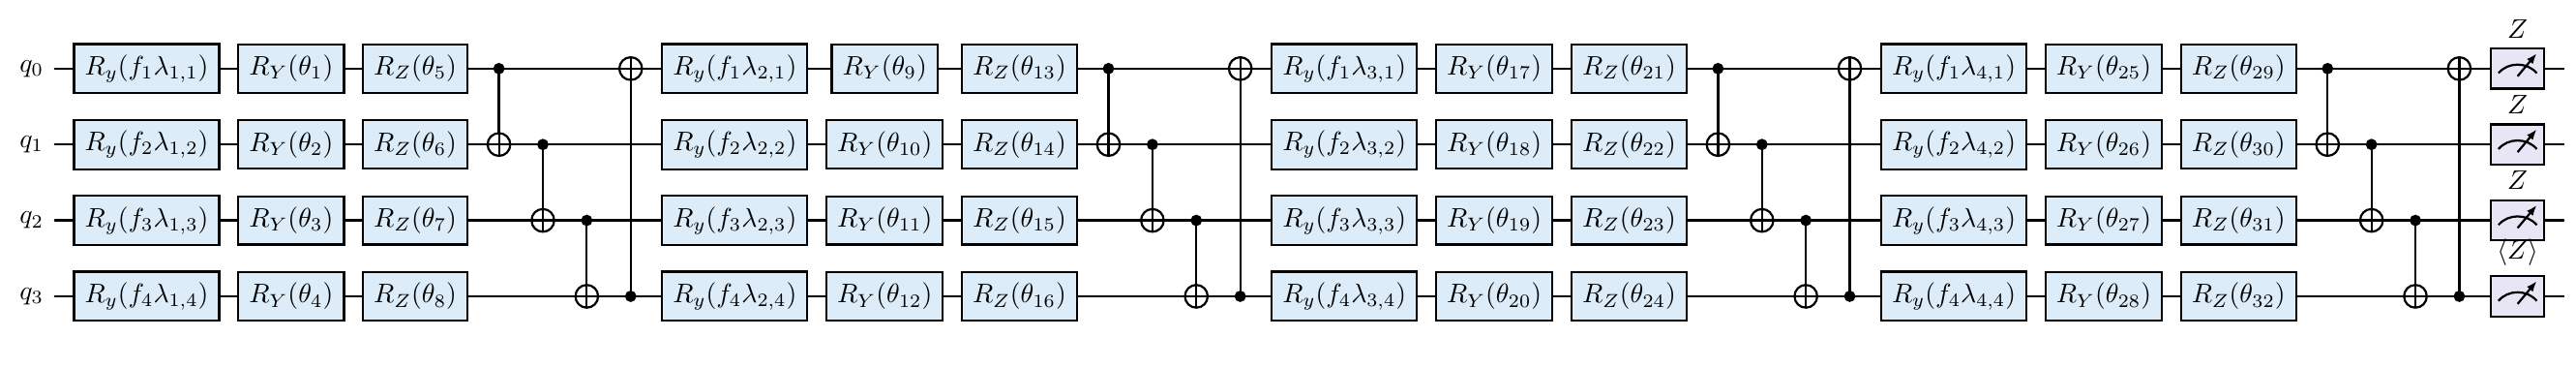

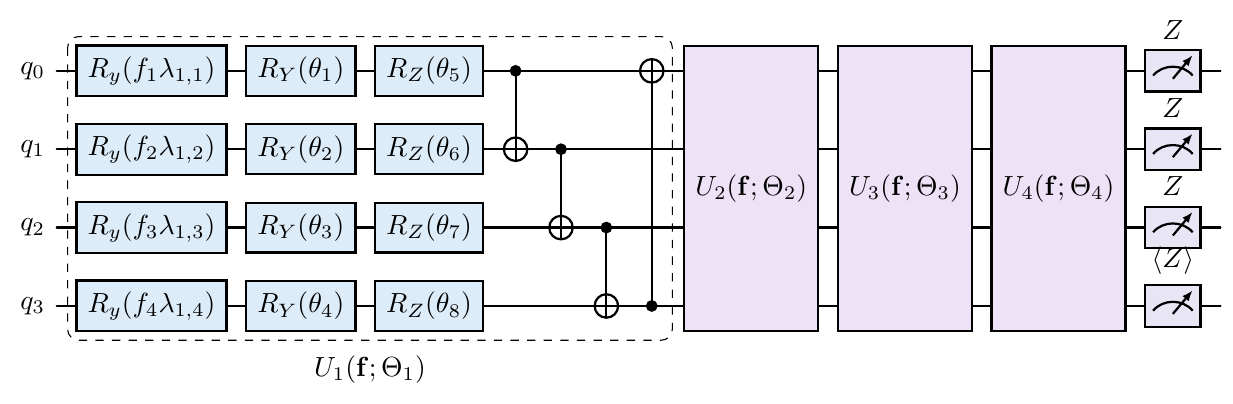

{'tex': PosixPath('tikz_output/pqdqn_compressed.tex'),
 'pdf': PosixPath('tikz_output/pqdqn_compressed.pdf'),
 'png': PosixPath('tikz_output/pqdqn_compressed.png')}

In [4]:
from qasp import create_qfunction, draw_qfunction

qfunction = create_qfunction({
    "ansatz": "AngleAnsatz",
    "ansatz_config": {"n_layers": 4, "rotations": "YZ", "reuploading": True,
                      "include_imprimitive": True, "imprimitive": "CNOT",
                      "imprimitive_pattern": "ring", "include_final_imprimitive": True},
    "feature_map": "AngleEmbedding",
    "feature_map_config": {"features": 4, "rotations": "Y", "input_scaling": True},
    "observables": "parity-like", "preset_actions": 4, "fc_layer": True, "fc_bias": True,
    "device": "default.qubit", "diff_method": "backprop",
}, n_qubits=4, n_actions=2)
qfunction_full = draw_qfunction(model=qfunction, output="tikz", tikz_options=FULL_TIKZ)
display_tikz(qfunction_full, "pqdqn_full")
qfunction_compressed = draw_qfunction(model=qfunction, output="tikz", tikz_options=COMPRESSED_TIKZ)
display_tikz(qfunction_compressed, "pqdqn_compressed")
# Equivalent entry points: qfunction.draw(...) and draw_model(model=qfunction, ...).


## Notes

- Every generated `.tex`, `.pdf`, and `.png` file is placed in `tikz_output/`.
- Set `standalone=False` when you want only the snippet to paste into an existing paper or Beamer presentation.
- Set `gate_colors=False` for monochrome output.
- `AngleEmbedding` is expanded into rotations labelled `f_i`; input scaling is shown as `f_i \lambda_i`.
- Increase `max_explicit_layers` to show more unitary blocks before QASP inserts an ellipsis.
- Automatic compression currently supports `AngleAnsatz` and `IQPAnsatz` with or without data reuploading (encoding must precede the first layer); mirrored overlap compression still requires `reuploading=False`.
